# Analytical Solution vs. Explicit Forward Euler vs. PINN

**Date:** 2026-11-06.

**Objective.** Solve the same initial-boundary value problem by three methods, compare them quantitatively, and explain the strengths and limitations of each.

$$
\frac{\partial u}{\partial t}=\beta\frac{\partial^2 u}{\partial x^2},\quad 0<x<1,\ 0<t\le T,\qquad \beta=10^{-5},\ T=12000,
$$
$$
u(x,0)=2x+\sin(2\pi x)+1,\qquad u(0,t)=1,\qquad u_x(1,t)=2.
$$

**Definition of done.** All derivations, plots and tables for items A1-D3 are present. The reference for all errors is the converged analytical series, and the common evaluation grid has 101 spatial points. The naive baseline is the steady profile $u_s(x)$: a method is only worthwhile if it beats $u_s$.

**Code layout.** The permanent code lives in `src/`, and this notebook only calls it. The full source is listed in the appendix at the end. Training the PINNs takes tens of minutes, so finished runs are stored in `weights/` and loaded from that cache. To retrain everything, delete the files in `weights/` and rerun the notebook.

## 1. Setup
Imports, paths and plot style. Each method keeps one color: analytical is black, Euler is orange, PINN is blue, the steady profile is gray.

In [1]:
from pathlib import Path
import sys, time

ROOT = Path.cwd().parent  # the notebook is run from notebooks/
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
import torch
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import NullFormatter
from scipy.integrate import quad

from src.analytic import exact_solution, series_coefficients, wave_numbers
from src.euler import diffusion_number, profile_at, solve_euler
from src.experiments import BOUNDARY_WEIGHTS, SEEDS, all_runs, ensure_trained, load_run
from src.metrics import max_abs_error, rmse
from src.pinn import DTYPE, PINNConfig, boundary_residuals, loss_terms, physics_residual, predict, sample_points
from src.problem import BETA, REPORT_TIMES, T, initial_condition, steady_state

torch.set_num_threads(1)  # one thread, like the numpy Euler code
TABLES = ROOT / "results" / "tables_en"
FIGURES = ROOT / "results" / "figures_en"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

COLORS = {"exact": "#0b0b0b", "euler": "#eb6834", "pinn": "#2a78d6", "steady": "#8a8984", "aqua": "#1baf7a", "yellow": "#eda100"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:.3e}")
pd.set_option("display.width", 160)

X_EVAL = np.linspace(0.0, 1.0, 101)  # common grid for all comparisons
ERROR_TIMES = (3000.0, 6000.0, 12000.0)


def reference(x, t):
    # At t = 0 the series converges slowly and the exact profile is known, so use it directly
    return initial_condition(np.asarray(x)) if t == 0 else exact_solution(x, t)


def save_table(frame, name):
    frame.to_csv(TABLES / f"{name}.csv", index=False)
    display(frame)


def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.14.1 | numpy 2.5.4


## 2. Incompatibility at the corner $(x,t)=(1,0)$
The initial profile and the Neumann condition contradict each other at this point:

$$u_x(x,0)=2+2\pi\cos(2\pi x)\ \Rightarrow\ u_x(1,0)=2+2\pi\approx 8.283,\quad\text{while the boundary requires } u_x(1,t)=2.$$

**Implications when comparing early-time solutions:**
- The exact solution is smooth for $t>0$, but the slope near the corner changes rapidly at small $t$. The slope jump spreads into a thin boundary layer of thickness about $\sqrt{\beta t}$: only $0.03$ at $t=100$, and already $0.17$ at $t=3000$.
- At $t=0$ the series converges slowly ($b_n\sim 1/n^2$), so the initial profile itself is used as the reference there.
- A grid with $\Delta x=0.025$ barely resolves this layer for $t\lesssim 100$.
- A PINN is a smooth function and cannot satisfy both conditions at the corner. Its error there does not mean the network is bad: the requirements at that point are incompatible.

The left corner is compatible: $u(0,0)=1$. Early times are analyzed quantitatively in section D2.

In [2]:
print("u_x(1, 0) from the initial profile =", 2 + 2 * np.pi, "| required by the boundary = 2 | jump =", 2 * np.pi)
print("left corner: u(0, 0) =", initial_condition(np.array(0.0)), "| required by the boundary = 1")

u_x(1, 0) from the initial profile = 8.283185307179586 | required by the boundary = 2 | jump = 6.283185307179586
left corner: u(0, 0) = 1.0 | required by the boundary = 1


---
# Part A. Analytical solution

## A1. Steady-state solution
From $u_{s,xx}=0$ we get $u_s(x)=Cx+D$. The conditions give $u_s(0)=D=1$ and $u_s'(1)=C=2$:

$$\boxed{u_s(x)=2x+1.}$$

**Physical meaning.** This is the temperature distribution the rod approaches as $t\to\infty$. The left end is held at temperature 1, and a constant gradient of 2 (a constant heat flux) is imposed at the right end. At equilibrium the temperature stops changing, so the flux $-\beta u_x$ is the same through every cross-section and the profile is linear. The initial condition does not affect $u_s$: all memory of it is in the transient part.

## A2. Problem for $v=u-u_s$
Substitute $u=v+u_s$. Since $u_s$ does not depend on $t$ and $u_{s,xx}=0$:

$$v_t=u_t=\beta u_{xx}=\beta(v_{xx}+u_{s,xx})=\beta v_{xx}.$$

The boundary conditions become homogeneous:
$$v(0,t)=u(0,t)-u_s(0)=1-1=0,\qquad v_x(1,t)=u_x(1,t)-u_s'(1)=2-2=0.$$

Initial condition:
$$v(x,0)=2x+\sin(2\pi x)+1-(2x+1)=\sin(2\pi x).$$

## A3. Separation of variables
Seek $v=X(x)\Theta(t)\not\equiv0$. Substitution into $v_t=\beta v_{xx}$ gives

$$\frac{\Theta'}{\beta\Theta}=\frac{X''}{X}=-\lambda.$$

The left side depends only on $t$ and the middle only on $x$, so both equal a constant. This gives two problems: $\Theta'=-\beta\lambda\Theta$ and $X''+\lambda X=0$, $X(0)=0$, $X'(1)=0$.

**Possible values of $\lambda$:**
- $\lambda<0$: $X=A\sinh(\mu x)$ from $X(0)=0$, then $X'(1)=A\mu\cosh\mu=0$ only for $A=0$.
- $\lambda=0$: $X=Ax$, then $X'(1)=A=0$.
- $\lambda=k^2>0$: $X=A\sin(kx)$, and $X'(1)=Ak\cos k=0$ gives $\cos k=0$, that is $k_n=(n+\tfrac12)\pi$, $n=0,1,\dots$

Hence $\Theta_n=e^{-\beta k_n^2t}$, and superposition gives

$$v(x,t)=\sum_{n=0}^{\infty}b_n\sin(k_nx)\,e^{-\beta k_n^2t},\qquad k_n=\left(n+\tfrac12\right)\pi.$$

**Coefficient formula.** The functions $\sin(k_nx)$ are orthogonal on $[0,1]$. For $n\ne m$:

$$\int_0^1\sin(k_nx)\sin(k_mx)\,dx=\frac12\left[\frac{\sin(k_n-k_m)}{k_n-k_m}-\frac{\sin(k_n+k_m)}{k_n+k_m}\right]=0,$$

because $k_n-k_m=(n-m)\pi$ and $k_n+k_m=(n+m+1)\pi$ are integer multiples of $\pi$, so both sines vanish. For $n=m$: $\int_0^1\sin^2(k_nx)\,dx=\tfrac12-\tfrac{\sin 2k_n}{4k_n}=\tfrac12$, because $\sin 2k_n=\sin((2n+1)\pi)=0$. Multiplying $v(x,0)=\sum b_n\sin(k_nx)$ by $\sin(k_mx)$ and integrating gives

$$b_n=2\int_0^1v(x,0)\sin(k_nx)\,dx.$$

**Evaluating the integral.** By the product-to-sum formula:

$$b_n=2\int_0^1\sin(2\pi x)\sin(k_nx)\,dx=\int_0^1\big[\cos((2\pi-k_n)x)-\cos((2\pi+k_n)x)\big]dx=\frac{\sin(2\pi-k_n)}{2\pi-k_n}-\frac{\sin(2\pi+k_n)}{2\pi+k_n}.$$

Since $\sin(2\pi\mp k_n)=\mp\sin k_n$ and $\sin k_n=(-1)^n$:

$$\boxed{b_n=-\sin k_n\,\frac{4\pi}{4\pi^2-k_n^2}=\frac{(-1)^{n+1}\,4\pi}{4\pi^2-k_n^2}=\frac{(-1)^{n+1}\,4}{\pi\left(4-(n+\frac12)^2\right)}.}$$

The denominator never vanishes: $n+\tfrac12\ne2$ for integer $n$, so $\sin(2\pi x)$ is not an eigenfunction of this problem. That is why the expansion contains many modes rather than one. The coefficients decay like $1/n^2$, which is a trace of the slope jump at the corner from section 2.

The formula is checked in two independent ways: symbolic integration and numerical quadrature.

In [3]:
# Check the b_n formula against symbolic and numerical integration
x_sym = sp.symbols("x", real=True)
rows = []
formula = series_coefficients(8)
for n, k in enumerate(wave_numbers(8)):
    k_sym = (sp.Integer(n) + sp.Rational(1, 2)) * sp.pi
    symbolic = 2 * sp.integrate(sp.sin(2 * sp.pi * x_sym) * sp.sin(k_sym * x_sym), (x_sym, 0, 1))
    numeric = 2 * quad(lambda z: np.sin(2 * np.pi * z) * np.sin(k * z), 0, 1)[0]
    rows.append({"n": n, "k_n": k, "b_n (formula)": formula[n], "b_n (sympy)": float(symbolic),
                 "b_n (quadrature)": numeric, "|formula - sympy|": abs(formula[n] - float(symbolic))})
save_table(pd.DataFrame(rows), "a3_coefficients")

,n,k_n,b_n (formula),b_n (sympy),b_n (quadrature),|formula - sympy|
0,0,1.571e+00,-3.395e-01,-3.395e-01,-3.395e-01,5.551e-17
1,1,4.712e+00,7.276e-01,7.276e-01,7.276e-01,1.110e-16
2,2,7.854e+00,5.659e-01,5.659e-01,5.659e-01,0.000e+00
3,3,1.100e+01,-1.543e-01,-1.543e-01,-1.543e-01,0.000e+00
4,4,1.414e+01,7.835e-02,7.835e-02,7.835e-02,0.000e+00
5,5,1.728e+01,-4.850e-02,-4.850e-02,-4.850e-02,1.388e-17
6,6,2.042e+01,3.329e-02,3.329e-02,3.329e-02,0.000e+00
7,7,2.356e+01,-2.437e-02,-2.437e-02,-2.437e-02,6.939e-18


**Conclusion.** The formula matches `sympy` and quadrature up to rounding errors. The largest contributions come from modes $n=1$ and $n=2$ rather than $n=0$, because the wavenumber $2\pi\approx6.28$ of the initial profile lies between $k_1\approx4.71$ and $k_2\approx7.85$.

## A4. Truncated series and convergence
We evaluate the series for $N=10,\dots,4000$ and compare it with a series of $N=20000$ terms, and at $t=0$ with the exact initial profile. Expectation before computing: for $t>0$ a few terms will suffice because $e^{-\beta k_n^2t}$ damps high modes, while at $t=0$ the error will fall slowly, roughly like $1/N$.

,N,"t=0, vs u(x,0)","t=3000, vs N=20000","t=6000, vs N=20000","t=12000, vs N=20000"
0,10,1.289e-01,4.441e-16,4.441e-16,4.441e-16
1,50,2.548e-02,0.000e+00,0.000e+00,0.000e+00
2,100,1.273e-02,0.000e+00,0.000e+00,0.000e+00
3,200,6.366e-03,0.000e+00,0.000e+00,0.000e+00
4,1000,1.273e-03,0.000e+00,0.000e+00,0.000e+00
5,2000,6.366e-04,0.000e+00,0.000e+00,0.000e+00
6,4000,3.183e-04,0.000e+00,0.000e+00,0.000e+00


Factor exp(-beta k_n^2 t):


,t=3000,t=6000,t=12000
n=0,0.9287,0.8624,0.7437
n=1,0.5137,0.2638,0.0696
n=2,0.1572,0.0247,0.0006
n=3,0.0266,0.0007,0.0000
n=4,0.0025,0.0000,0.0000


Time scale of the first mode 1 / (beta k_0^2) = 40528 | T = 12000


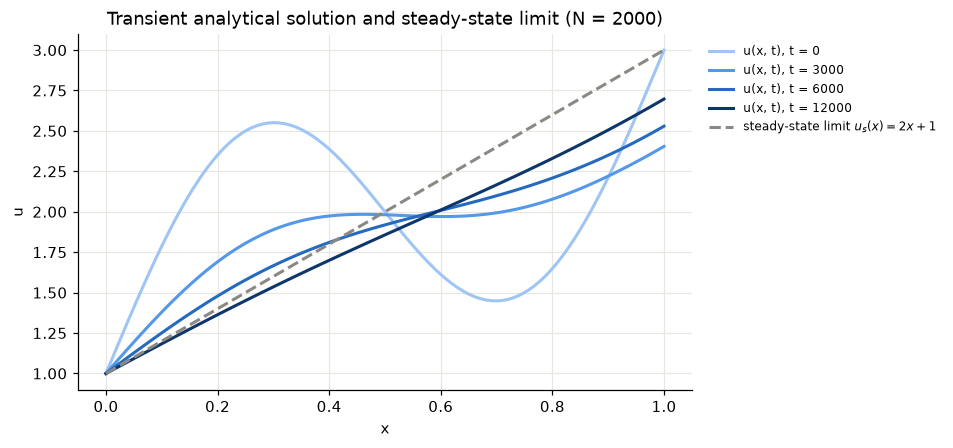

,t,max|u - u_s| = max|v|,"RMSE(u, u_s)"
0,0.000e+00,1.000e+00,7.036e-01
1,3.000e+03,5.958e-01,3.522e-01
2,6.000e+03,4.707e-01,2.488e-01
3,1.200e+04,3.028e-01,1.825e-01


In [4]:
rows = []
for n_terms in (10, 50, 100, 200, 1000, 2000, 4000):
    row = {"N": n_terms, "t=0, vs u(x,0)": max_abs_error(exact_solution(X_EVAL, 0.0, n_terms), initial_condition(X_EVAL))}
    for t in REPORT_TIMES[1:]:
        row[f"t={t:.0f}, vs N=20000"] = max_abs_error(exact_solution(X_EVAL, t, n_terms), exact_solution(X_EVAL, t, 20000))
    rows.append(row)
save_table(pd.DataFrame(rows), "a4_series_convergence")

# How fast the first modes decay by different times
k = wave_numbers(5)
print("Factor exp(-beta k_n^2 t):")
display(pd.DataFrame({f"t={t:.0f}": np.exp(-BETA * k**2 * t) for t in REPORT_TIMES[1:]}, index=[f"n={n}" for n in range(5)]).style.format("{:.4f}"))
print("Time scale of the first mode 1 / (beta k_0^2) =", round(1 / (BETA * k[0] ** 2)), "| T =", int(T))

shades = ["#9ec5f4", "#5598e7", "#256abf", "#0d366b"]
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for t, color in zip(REPORT_TIMES, shades):
    ax.plot(X_EVAL, exact_solution(X_EVAL, t, 2000), color=color, label=f"u(x, t), t = {t:.0f}")
ax.plot(X_EVAL, steady_state(X_EVAL), "--", color=COLORS["steady"], label="steady-state limit $u_s(x)=2x+1$")
ax.set(xlabel="x", ylabel="u", title="Transient analytical solution and steady-state limit (N = 2000)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
save_figure(fig, "a4_analytic_profiles")

rows = [{"t": t, "max|u - u_s| = max|v|": max_abs_error(reference(X_EVAL, t), steady_state(X_EVAL)),
         "RMSE(u, u_s)": rmse(reference(X_EVAL, t), steady_state(X_EVAL))} for t in REPORT_TIMES]
save_table(pd.DataFrame(rows), "a4_distance_from_steady_state")

**Conclusion.**
- **Convergence.** For $t\ge3000$ even $N=10$ reaches machine precision, because $e^{-\beta k_n^2t}$ eliminates the higher modes. At $t=0$ the error falls like $\approx1.27/N$ (doubling $N$ halves the error), consistent with $b_n\sim1/n^2$. So $N=50$ still gives $2.5\cdot10^{-2}$ at $t=0$, and the initial profile serves as the reference there. All comparisons use $N=2000$.
- **Transient solution vs. limit.** These are different functions: at $t=T$ the distance from $u_s$ is still $\max|v|=0.30$, RMSE $0.18$. The time scale of the first mode, $1/(\beta k_0^2)\approx40500$, is well above $T=12000$, and its factor at $T$ is only down to $0.74$. Reaching 1% of this mode's initial amplitude takes $t\approx190000$. So the steady profile is not reached within the given interval and serves only as a baseline.

---
# Part B. Explicit Forward Euler

## B1. Scheme and stability
Grid: $x_j=j\Delta x$, $t_m=m\Delta t$, $U_j^m\approx u(x_j,t_m)$. Replace the derivatives with differences:

$$u_t(x_j,t_m)=\frac{U_j^{m+1}-U_j^m}{\Delta t}+O(\Delta t),\qquad u_{xx}(x_j,t_m)=\frac{U_{j-1}^m-2U_j^m+U_{j+1}^m}{(\Delta x)^2}+O(\Delta x^2).$$

Substituting into the equation and solving for the new level:

$$U_j^{m+1}=U_j^m+s\,(U_{j-1}^m-2U_j^m+U_{j+1}^m),\qquad s=\frac{\beta\Delta t}{(\Delta x)^2}.$$

**Stability (von Neumann analysis).** Substitute the harmonic $U_j^m=G^me^{\mathrm{i}j\theta}$:

$$G=1+s(e^{-\mathrm{i}\theta}-2+e^{\mathrm{i}\theta})=1-4s\sin^2\frac{\theta}{2}.$$

The condition $|G|\le1$ for all $\theta$ is equivalent to $\boxed{s\le\tfrac12.}$ The most dangerous mode is the sawtooth with $\theta=\pi$, for which $G=1-4s$.

**For the specified grid** $\Delta x=1/40$, $\Delta t=20$:
$$s=\frac{10^{-5}\cdot20}{(1/40)^2}=10^{-5}\cdot20\cdot1600=0.32\le0.5,$$
so the scheme is stable.

**Boundary conditions.** On the left $U_0^{m+1}=1$. On the right, a first-order one-sided difference:

$$\frac{U_J^{m+1}-U_{J-1}^{m+1}}{\Delta x}=2\ \Rightarrow\ U_J^{m+1}=U_{J-1}^{m+1}+2\Delta x.$$

## B2. Implementation
The scheme is written by hand, without library solvers (`src/euler.py`, listed in the appendix). It is one time loop with a vectorized update of the interior nodes, followed by the two boundary conditions.

In [5]:
print("s =", diffusion_number(40, 600))
x_c, t_c, U_c = solve_euler(n_intervals=40, n_steps=600, neumann_order=1)
print("spatial nodes:", x_c.size, "| time levels:", t_c.size, "| dx =", x_c[1] - x_c[0], "| dt =", t_c[1] - t_c[0])
print("solution range:", U_c.min().round(4), "...", U_c.max().round(4))

s = 0.32
spatial nodes: 41 | time levels: 601 | dx = 0.025 | dt = 20.0
solution range: 1.0 ... 3.0


## B3. Comparison with the analytical series and solution map
Each panel shows one time, with colors fixed per method. The 41-node numerical solution is linearly interpolated to the common 101-point grid. Interpolation itself adds an error of order $O(\Delta x^2)$, so it is estimated separately by interpolating the exact solution from the same 41 nodes.

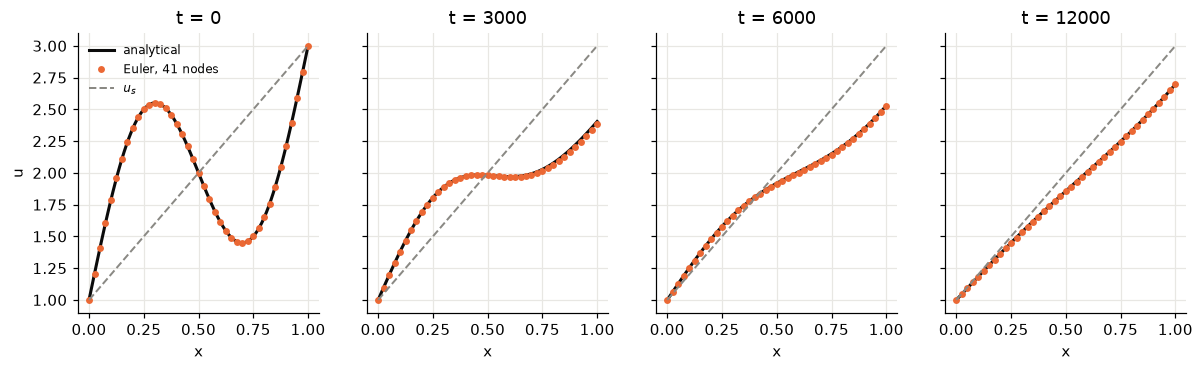

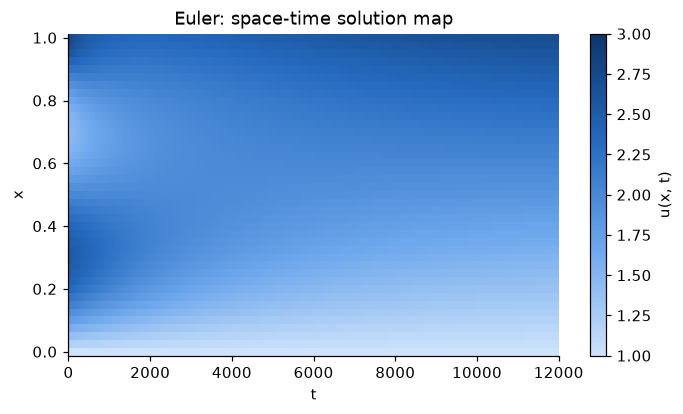

,t,Euler max error,Euler RMSE,max error from interpolation alone
0,0.000e+00,2.951e-03,1.583e-03,2.951e-03
1,3.000e+03,1.995e-02,9.337e-03,9.165e-04
2,6.000e+03,8.519e-03,5.173e-03,3.384e-04
3,1.200e+04,3.381e-03,2.284e-03,1.293e-04


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, t in zip(axes, REPORT_TIMES):
    ax.plot(X_EVAL, reference(X_EVAL, t), color=COLORS["exact"], label="analytical")
    ax.plot(x_c, profile_at(t_c, U_c, t), "o", ms=3.5, color=COLORS["euler"], label="Euler, 41 nodes")
    ax.plot(X_EVAL, steady_state(X_EVAL), "--", lw=1.3, color=COLORS["steady"], label="$u_s$")
    ax.set(title=f"t = {t:.0f}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend(loc="upper left", fontsize=8)
save_figure(fig, "b3_euler_vs_analytic")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
image = ax.pcolormesh(t_c, x_c, U_c.T, cmap=BLUES, shading="auto")
fig.colorbar(image, ax=ax, label="u(x, t)")
ax.set(xlabel="t", ylabel="x", title="Euler: space-time solution map")
ax.grid(False)
save_figure(fig, "b3_euler_heatmap")

rows = []
for t in REPORT_TIMES:
    euler_on_eval = np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))
    interp_only = np.interp(X_EVAL, x_c, reference(x_c, t))
    rows.append({"t": t, "Euler max error": max_abs_error(euler_on_eval, reference(X_EVAL, t)),
                 "Euler RMSE": rmse(euler_on_eval, reference(X_EVAL, t)),
                 "max error from interpolation alone": max_abs_error(interp_only, reference(X_EVAL, t))})
save_table(pd.DataFrame(rows), "b3_euler_errors")

**Conclusion.** Visually the scheme matches the analytical series on all four profiles. RMSE falls with time: $9.3\cdot10^{-3}$, $5.2\cdot10^{-3}$, $2.3\cdot10^{-3}$. That is 38-80 times better than the steady baseline (0.35, 0.25, 0.18). The interpolation contribution is small for $t>0$: at $t=3000$ it gives $9\cdot10^{-4}$ out of $2\cdot10^{-2}$. At $t=0$ the error at the nodes is zero, and the whole error on the common grid, $3\cdot10^{-3}$, comes from interpolation.

## B4. Grid refinement and the influence of the first-order Neumann condition
We keep $s=0.32$ constant: halving $\Delta x$ divides $\Delta t$ by 4, so the stability restriction holds on all grids. Besides the specified scheme we run a control with the same interior stencil but a second-order Neumann condition through a ghost node, $U_{J+1}=U_{J-1}+4\Delta x$. The two differ only at the right boundary, so their difference shows the contribution of this approximation alone.

**Expectation from Taylor expansion.** Expanding around $x=1$:
$$\frac{u(1,t)-u(1-\Delta x,t)}{\Delta x}=u_x(1,t)-\frac{\Delta x}{2}u_{xx}(1,t)+O(\Delta x^2).$$
So the condition $U_J-U_{J-1}=2\Delta x$ actually imposes slope 2 at the middle of the last cell, and the boundary error equals $\frac{\Delta x}{2}u_{xx}(1,t)$, which is of order $O(\Delta x)$. The interior stencil at constant $s$ is more accurate: $O(\Delta t)+O(\Delta x^2)=O(\Delta x^2)$. The first-order boundary should therefore dominate the whole error.

,Neumann order,dx,dt,s,"time, s",max t=3000,RMSE t=3000,max t=6000,RMSE t=6000,max t=12000,RMSE t=12000,"order p, RMSE t=3000","order p, RMSE t=6000","order p, RMSE t=12000"
0,1,2.500e-02,2.000e+01,3.200e-01,1.962e-03,1.995e-02,9.337e-03,8.519e-03,5.173e-03,3.381e-03,2.284e-03,NaN,NaN,NaN
1,1,1.250e-02,5.000e+00,3.200e-01,7.715e-03,1.121e-02,5.262e-03,5.093e-03,3.093e-03,2.097e-03,1.431e-03,8.273e-01,7.421e-01,6.745e-01
2,1,6.250e-03,1.250e+00,3.200e-01,3.391e-02,5.907e-03,2.777e-03,2.751e-03,1.675e-03,1.160e-03,8.013e-04,9.222e-01,8.852e-01,8.364e-01
3,1,3.125e-03,3.125e-01,3.200e-01,1.404e-01,3.028e-03,1.424e-03,1.426e-03,8.693e-04,6.085e-04,4.232e-04,9.630e-01,9.458e-01,9.211e-01
4,2,2.500e-02,2.000e+01,3.200e-01,2.086e-03,1.562e-03,9.889e-04,1.182e-03,6.502e-04,8.066e-04,4.125e-04,NaN,NaN,NaN
5,2,1.250e-02,5.000e+00,3.200e-01,8.305e-03,3.891e-04,2.473e-04,2.952e-04,1.626e-04,2.014e-04,1.031e-04,2.000e+00,2.000e+00,2.000e+00
6,2,6.250e-03,1.250e+00,3.200e-01,3.609e-02,9.772e-05,6.182e-05,7.384e-05,4.065e-05,5.042e-05,2.578e-05,2.000e+00,2.000e+00,2.000e+00
7,2,3.125e-03,3.125e-01,3.200e-01,1.497e-01,2.431e-05,1.546e-05,1.845e-05,1.016e-05,1.259e-05,6.444e-06,2.000e+00,2.000e+00,2.000e+00


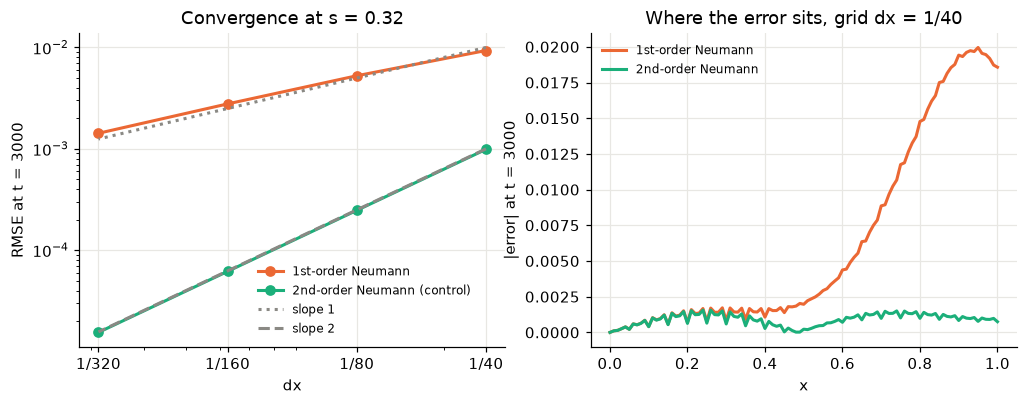

dx = 1/80, dt = 20: s = 1.28 | final max|U| = nan


In [7]:
# Grids with the same s = 0.32. Only the 4 reported levels are kept in memory
rows, errors_by_order = [], {1: [], 2: []}
for order in (1, 2):
    for n_intervals, n_steps in ((40, 600), (80, 2400), (160, 9600), (320, 38400)):
        start = time.perf_counter()
        x, ts, U = solve_euler(n_intervals, n_steps, neumann_order=order, store_every=n_steps // 4)
        elapsed = time.perf_counter() - start
        row = {"Neumann order": order, "dx": 1 / n_intervals, "dt": T / n_steps,
               "s": diffusion_number(n_intervals, n_steps), "time, s": elapsed}
        for t in ERROR_TIMES:
            pred = np.interp(X_EVAL, x, profile_at(ts, U, t))
            row[f"max t={t:.0f}"] = max_abs_error(pred, reference(X_EVAL, t))
            row[f"RMSE t={t:.0f}"] = rmse(pred, reference(X_EVAL, t))
        rows.append(row)
        errors_by_order[order].append(row)
refine = pd.DataFrame(rows)
# Observed order p = log2(error on the coarse grid / error on the twice finer grid)
for t in ERROR_TIMES:
    refine[f"order p, RMSE t={t:.0f}"] = refine.groupby("Neumann order")[f"RMSE t={t:.0f}"].transform(lambda s_: np.log2(s_.shift(1) / s_))
save_table(refine, "b4_euler_refinement")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for order, color, label in ((1, COLORS["euler"], "1st-order Neumann"), (2, COLORS["aqua"], "2nd-order Neumann (control)")):
    part = refine[refine["Neumann order"] == order]
    axes[0].loglog(part["dx"], part["RMSE t=3000"], "o-", color=color, label=label)
axes[0].loglog(refine["dx"][:4], 0.4 * refine["dx"][:4], ":", color=COLORS["steady"], label="slope 1")
axes[0].loglog(refine["dx"][:4], 1.6 * refine["dx"][:4] ** 2, "--", color=COLORS["steady"], label="slope 2")
axes[0].set(xlabel="dx", ylabel="RMSE at t = 3000", title="Convergence at s = 0.32")
axes[0].xaxis.set_minor_formatter(NullFormatter())
axes[0].set_xticks([1 / 320, 1 / 160, 1 / 80, 1 / 40], ["1/320", "1/160", "1/80", "1/40"])
axes[0].legend(fontsize=8)

for order, color, label in ((1, COLORS["euler"], "1st-order Neumann"), (2, COLORS["aqua"], "2nd-order Neumann")):
    x, ts, U = solve_euler(40, 600, neumann_order=order, store_every=150)
    axes[1].plot(X_EVAL, np.abs(np.interp(X_EVAL, x, profile_at(ts, U, 3000.0)) - reference(X_EVAL, 3000.0)), color=color, label=label)
axes[1].set(xlabel="x", ylabel="|error| at t = 3000", title="Where the error sits, grid dx = 1/40")
axes[1].legend(fontsize=8)
save_figure(fig, "b4_refinement")

# Check of the stability restriction: keep the time step and refine only x
with np.errstate(over="ignore", invalid="ignore"):
    _, _, unstable = solve_euler(80, 600, neumann_order=1, store_every=600)
print("dx = 1/80, dt = 20: s =", diffusion_number(80, 600), "| final max|U| =", np.abs(unstable[-1]).max())

**Conclusion.**
- **Specified scheme.** Each refinement nearly halves RMSE. The observed order at $t=3000$ is 0.83, 0.92, 0.96, approaching 1 as the Taylor expansion predicts. On coarse grids the order is below 1 because the factor $u_{xx}(1,t)$ is large at early times and the grid has not yet reached the asymptotic regime.
- **Cause of the first order.** The control scheme differs only at the right boundary and gives order exactly 2.00 at all times. So the Neumann condition determines the order of the error: one boundary formula degrades the accuracy of the whole solution, because the flux error diffuses into the domain. In the right plot at $t=3000$ it already occupies the right half of the domain, while in the left half the two schemes nearly coincide. The sawtooth on the lines comes from interpolation between nodes.
- **Practical weight.** On the same grid $\Delta x=1/40$ and in almost the same time, the second-order error is 9 times smaller ($9.9\cdot10^{-4}$ vs. $9.3\cdot10^{-3}$ at $t=3000$). The first-order scheme on grid $1/320$ is still worse than second order on $1/40$ ($1.4\cdot10^{-3}$), though it takes about 70 times longer.
- **Stability.** With $\Delta x=1/80$ and the old $\Delta t=20$ we get $s=1.28>0.5$, and the solution breaks down to `nan`. Refining $x$ alone is not allowed: $\Delta t$ must fall like $\Delta x^2$.

---
# Part C. Physics-Informed Neural Network

## C1. Scaled residual and loss functions
Introduce $\tau=t/T\in[0,1]$. By the chain rule $\dfrac{\partial u_\theta}{\partial t}=\dfrac{\partial u_\theta}{\partial\tau}\dfrac{d\tau}{dt}=\dfrac1T\dfrac{\partial u_\theta}{\partial\tau}$. The $x$ derivative does not change. Substituting into the equation gives

$$r_\theta(x,\tau)=\frac1T\frac{\partial u_\theta}{\partial\tau}-\beta\frac{\partial^2u_\theta}{\partial x^2}.$$

**Loss functions.** For collocation points $(x_i^r,\tau_i^r)$, initial points $x_i^{0}$ and boundary points $\tau_i^b$:

$$L_{\text{phys}}=\frac1{N_r}\sum_{i=1}^{N_r}r_\theta(x_i^r,\tau_i^r)^2,$$
$$L_{\text{IC}}=\frac1{N_0}\sum_{i=1}^{N_0}\big(u_\theta(x_i^0,0)-2x_i^0-\sin(2\pi x_i^0)-1\big)^2,$$
$$L_{\text{D}}=\frac1{N_b}\sum_{i=1}^{N_b}\big(u_\theta(0,\tau_i^b)-1\big)^2,\qquad L_{\text{N}}=\frac1{N_b}\sum_{i=1}^{N_b}\big(\partial_xu_\theta(1,\tau_i^b)-2\big)^2,$$
$$L=\lambda_{\text{phys}}L_{\text{phys}}+\lambda_{\text{IC}}L_{\text{IC}}+\lambda_{\text{D}}L_{\text{D}}+\lambda_{\text{N}}L_{\text{N}}.$$

**Scale of the residual.** Multiplying the equation by $T$ gives the dimensionless form $\tilde r=u_\tau-\beta Tu_{xx}=u_\tau-0.12\,u_{xx}$, whose terms are of order one. Since $\tilde r=Tr$, we have $\tilde r^2=T^2r^2$. So the weight $\lambda_{\text{phys}}=T^2=1.44\cdot10^8$ means exactly training on the dimensionless residual. The residual $r$ as originally stated is correct: this is only a different scale of the same quantity.

**Automatic differentiation.** The network is a composition of simple operations, so derivatives of the output with respect to the inputs are computed exactly by the chain rule (up to rounding, with no finite differences):
- $x$ and $\tau$ are declared with `requires_grad=True`, and $u=u_\theta(x,\tau)$ is computed;
- `torch.autograd.grad(u.sum(), (x, tau), create_graph=True)` gives $u_x$ and $u_\tau$. The sum yields pointwise derivatives, since each point affects only its own term;
- a second call for `u_x.sum()` with respect to $x$ gives $u_{xx}$;
- `create_graph=True` keeps the graph of the derivatives. Without it we could not take the second derivative or call `backward()` from the loss to the weights $\theta$, since the loss itself contains network derivatives.

## C2. Implementation
Code: `src/pinn.py`, listed in the appendix. The exact solution is not used in the loss; it appears only for evaluation in C4 and Part D.

**Changes from the reference baseline, and why:**

| Setting | Reference baseline | Used here | Reason |
|---|---|---|---|
| Adam iterations | 1000 | 20000 | After 1000 iterations the network has not learned the initial profile, see the comparison below |
| Physics weight $\lambda_{\text{phys}}$ | not specified | $T^2$ | Without it the physics has almost no effect on training, see C3 |
| Learning rate | not specified | cosine decay $10^{-3}\to10^{-5}$ | Less noise at the end of training |
| Input | $(x,\tau)$ | scaled to $[-1,1]$ inside the network | $\tanh$ trains more easily this way |
| Number precision | not specified | float64 | $L_{\text{phys}}\sim10^{-12}$, so derivatives need precision |
| Architecture | 3 layers of 32, $\tanh$ | unchanged | |

**Settings were chosen by the losses, without using the exact solution as a criterion.** Six variants were compared beforehand with seed 0 and 20000 iterations: fixed or resampled points, weight $\lambda_{\text{IC}}\in\{1,10\}$, boundary weight $\in\{1,10\}$. Fixed points with unit weights gave the lowest component training losses: $L_{\text{IC}}=2.2\cdot10^{-4}$, $L_{\text{N}}=2.4\cdot10^{-5}$ vs. $1.1\cdot10^{-3}$ and $9.4\cdot10^{-5}$ with resampling. This comparison is biased toward fixed points, since the loss is computed on those same points. So in C3 the variants are also compared on independent points.

Main runs: 3 seeds. Run `main_seed0` is trained alone on one thread, so its time goes into the report. The others ran in parallel with 4 processes and slowed each other down, so their times are not used for the cost comparison.

trained in this execution: 0 | total runs: 15
Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=32, bias=True)
  (5): Tanh()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
network parameters: 2241


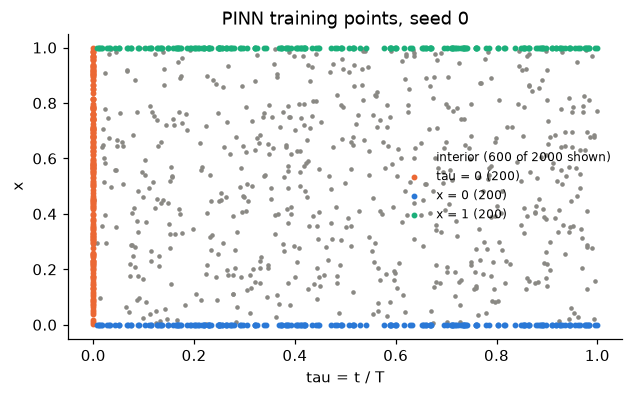

In [8]:
cfg = PINNConfig()
trained_now = ensure_trained(processes=4)  # trains only what is missing from weights/
print("trained in this execution:", len(trained_now), "| total runs:", len(all_runs()))

model, main_run = load_run("main_seed0")
n_params = sum(p.numel() for p in model.parameters())
print(model.net)
print("network parameters:", n_params)

# Preview of the points the network learns on: for a PINN these are the training data
points = sample_points(cfg, torch.Generator().manual_seed(cfg.seed))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(points["tau_r"][:600], points["x_r"][:600], s=4, color=COLORS["steady"], label=f"interior (600 of {cfg.n_interior} shown)")
ax.scatter(np.zeros(cfg.n_initial), points["x_ic"], s=8, color=COLORS["euler"], label=f"tau = 0 ({cfg.n_initial})")
ax.scatter(points["tau_b"], np.zeros(cfg.n_boundary), s=8, color=COLORS["pinn"], label=f"x = 0 ({cfg.n_boundary})")
ax.scatter(points["tau_b"], np.ones(cfg.n_boundary), s=8, color=COLORS["aqua"], label=f"x = 1 ({cfg.n_boundary})")
ax.set(xlabel="tau = t / T", ylabel="x", title="PINN training points, seed 0")
ax.legend(fontsize=8, loc="center right")
ax.grid(False)
save_figure(fig, "c2_sampled_points")

## C3. Losses during training

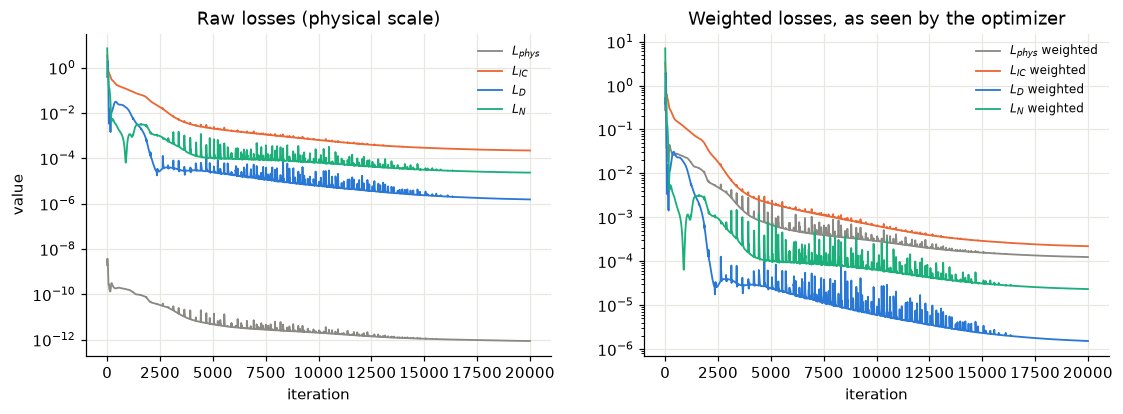

,Setting,Value
0,Architecture,"(x, tau) -> 3 layers of 32 tanh -> u"
1,Network parameters,2241
2,Points interior / at tau=0 / on each boundary,2000 / 200 / 200
3,Points,"uniform random, fixed for the whole training"
4,Weights physics / IC / D / N,1.44e+08 / 1.0 / 1.0 / 1.0
5,Seed,0
6,Optimizer,"Adam, lr 0.001 -> 1e-05 with cosine decay"
7,Iterations,20000
8,"Training time, s (1 CPU thread, Apple M4)",3.584e+02


,term,unweighted,weight,weighted,"start, unweighted"
0,physics,8.743e-13,1.440e+08,1.259e-04,1.909e-09
1,initial,2.230e-04,1.000e+00,2.230e-04,3.354e+00
2,dirichlet,1.560e-06,1.000e+00,1.560e-06,3.844e-01
3,neumann,2.357e-05,1.000e+00,2.357e-05,7.014e+00


In [9]:
history = main_run["history"]
names = {"physics": "$L_{phys}$", "initial": "$L_{IC}$", "dirichlet": "$L_D$", "neumann": "$L_N$"}
line_colors = {"physics": COLORS["steady"], "initial": COLORS["euler"], "dirichlet": COLORS["pinn"], "neumann": COLORS["aqua"]}
weights = {"physics": cfg.weight_physics, "initial": cfg.weight_initial, "dirichlet": cfg.weight_dirichlet, "neumann": cfg.weight_neumann}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for name, label in names.items():
    axes[0].semilogy(history["iteration"], history[name], lw=1.2, color=line_colors[name], label=label)
    axes[1].semilogy(history["iteration"], weights[name] * history[name], lw=1.2, color=line_colors[name], label=f"{label} weighted")
axes[0].set(title="Raw losses (physical scale)", xlabel="iteration", ylabel="value")
axes[1].set(title="Weighted losses, as seen by the optimizer", xlabel="iteration")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
save_figure(fig, "c3_losses")

settings = pd.DataFrame([
    ("Architecture", f"(x, tau) -> {cfg.hidden_layers} layers of {cfg.hidden_units} tanh -> u"),
    ("Network parameters", n_params),
    ("Points interior / at tau=0 / on each boundary", f"{cfg.n_interior} / {cfg.n_initial} / {cfg.n_boundary}"),
    ("Points", "uniform random, fixed for the whole training"),
    ("Weights physics / IC / D / N", f"{cfg.weight_physics:.3g} / {cfg.weight_initial} / {cfg.weight_dirichlet} / {cfg.weight_neumann}"),
    ("Seed", cfg.seed),
    ("Optimizer", f"Adam, lr {cfg.lr} -> {cfg.lr_final} with cosine decay"),
    ("Iterations", cfg.iterations),
    ("Training time, s (1 CPU thread, Apple M4)", round(main_run["seconds"], 1)),
], columns=["Setting", "Value"])
save_table(settings, "c3_settings")

final = pd.DataFrame([{"term": name, "unweighted": np.mean(history[name][-100:]), "weight": weights[name],
                       "weighted": weights[name] * np.mean(history[name][-100:]),
                       "start, unweighted": history[name][0]} for name in names])
save_table(final, "c3_final_losses")

In [10]:
# Check without the exact solution: all losses on independent points the network has not seen
fresh = torch.Generator().manual_seed(12345)
fresh_points = {"x_r": torch.rand(50000, 1, generator=fresh, dtype=DTYPE), "tau_r": torch.rand(50000, 1, generator=fresh, dtype=DTYPE),
                "x_ic": torch.rand(20000, 1, generator=fresh, dtype=DTYPE), "tau_b": torch.rand(20000, 1, generator=fresh, dtype=DTYPE)}
corner = (fresh_points["tau_r"] < 0.02) & (fresh_points["x_r"] > 0.9)  # region near the corner (1, 0)
rows = []
for name in ("main_seed0", "main_seed1", "main_seed2", "resample_seed0"):
    m, run = load_run(name)
    terms = loss_terms(m, fresh_points)
    scaled = (T * physics_residual(m, fresh_points["x_r"], fresh_points["tau_r"]).detach()) ** 2
    rows.append({"run": name, "T^2 L_phys, train": T**2 * np.mean(run["history"]["physics"][-100:]),
                 "T^2 L_phys, fresh": scaled.mean().item(), "fresh, without corner": scaled[~corner].mean().item(),
                 "corner share of residual": (scaled[corner].sum() / scaled.sum()).item(),
                 "L_IC, fresh": terms["initial"].item(), "L_D, fresh": terms["dirichlet"].item(), "L_N, fresh": terms["neumann"].item()})
fresh_table = pd.DataFrame(rows)
fresh_table["sum of losses, fresh"] = fresh_table[["T^2 L_phys, fresh", "L_IC, fresh", "L_D, fresh", "L_N, fresh"]].sum(axis=1)
save_table(fresh_table, "c3_fresh_points_check")

# Effect of the iteration count and the physics weight. Each run changes one setting
rows = []
for name, label in (("baseline_1000", "1000 iterations"), ("main_seed0", "20000 iterations, physics weight T^2"), ("no_physics_weight", "20000 iterations, physics weight 1")):
    m, run = load_run(name)
    h = run["history"]
    row = {"run": label, "L_phys": np.mean(h["physics"][-10:]), "L_IC": np.mean(h["initial"][-10:]),
           "L_D": np.mean(h["dirichlet"][-10:]), "L_N": np.mean(h["neumann"][-10:])}
    for t in ERROR_TIMES:
        row[f"RMSE t={t:.0f}"] = rmse(predict(m, X_EVAL, t), reference(X_EVAL, t))
    rows.append(row)
save_table(pd.DataFrame(rows), "c3_settings_effect")

,run,"T^2 L_phys, train","T^2 L_phys, fresh","fresh, without corner",corner share of residual,"L_IC, fresh","L_D, fresh","L_N, fresh","sum of losses, fresh"
0,main_seed0,1.259e-04,2.060e-03,5.332e-04,7.420e-01,2.318e-04,1.491e-06,1.376e-04,2.431e-03
1,main_seed1,1.223e-04,8.299e-04,5.589e-04,3.286e-01,6.879e-04,2.547e-06,8.610e-06,1.529e-03
2,main_seed2,1.147e-04,4.947e-04,2.365e-04,5.234e-01,3.570e-04,1.103e-06,1.329e-05,8.661e-04
3,resample_seed0,4.443e-04,4.933e-04,2.786e-04,4.370e-01,1.110e-03,6.675e-06,9.608e-05,1.706e-03


,run,L_phys,L_IC,L_D,L_N,RMSE t=3000,RMSE t=6000,RMSE t=12000
0,1000 iterations,1.940e-10,1.566e-01,2.412e-02,1.917e-03,5.851e-02,1.853e-02,2.719e-02
1,"20000 iterations, physics weight T^2",8.641e-13,2.201e-04,1.526e-06,2.323e-05,1.361e-03,1.344e-03,1.197e-03
2,"20000 iterations, physics weight 1",4.218e-07,6.582e-05,5.178e-07,1.544e-05,6.134e-01,7.680e-01,6.234e-01


**Loss imbalance.**
- *Without a weight the physics is invisible.* At the start of training $L_{\text{N}}\approx7$ and $L_{\text{IC}}\approx3.4$, while $L_{\text{phys}}\approx2\cdot10^{-9}$. The reason is scale: $r=\tfrac1Tu_\tau-\beta u_{xx}$ contains the factors $8.3\cdot10^{-5}$ and $10^{-5}$. This is a difference of scale, not a sign that the equation is already satisfied.
- *What happens without scaling.* The run with $\lambda_{\text{phys}}=1$ learned the initial and boundary conditions very well, but $T^2L_{\text{phys}}\approx61$, so the equation is not solved. Its RMSE of 0.61-0.77 is worse than even the steady baseline (0.18-0.35). The small value $L_{\text{phys}}=4.2\cdot10^{-7}$ is misleading here: terms must be compared on one scale.
- *With the weight $T^2$* the physics and initial-condition contributions become the same order ($1.3\cdot10^{-4}$ and $2.2\cdot10^{-4}$), and the optimizer accounts for both. $L_{\text{D}}\approx1.6\cdot10^{-6}$ is the smallest: a constant on the left boundary is the easiest to learn. $L_{\text{IC}}$ stays the largest because of the corner incompatibility and the bends of the sine.
- *Iteration count.* After the baseline 1000 iterations $L_{\text{IC}}\approx0.16$ and the RMSE at $t=3000$ is $5.9\cdot10^{-2}$. That beats the baseline but is 6 times worse than the specified Euler scheme. Hence 20000 iterations in the main run.

**Check on fresh points.** The residual on independent points is higher than on the training points: for seed 0, $2.1\cdot10^{-3}$ vs. $1.3\cdot10^{-4}$. A large part of this gap sits near the corner, where almost no collocation points fall (corner share 0.33-0.74 with 0.2% of the area). Without the corner the gap is still about 2-5 times, so fixed points cause mild overfitting. On fresh points the resampling variant has a lower physics residual than seed 0 but a higher $L_{\text{IC}}$ (sum of losses $1.7\cdot10^{-3}$). The main seeds have a sum of $0.9$-$2.4\cdot10^{-3}$, so **neither variant has a demonstrable advantage**: the difference does not exceed the spread between seeds. The settings were kept, and this remains a limitation of the work.

## C4. Comparison with the analytical solution and boundary conditions

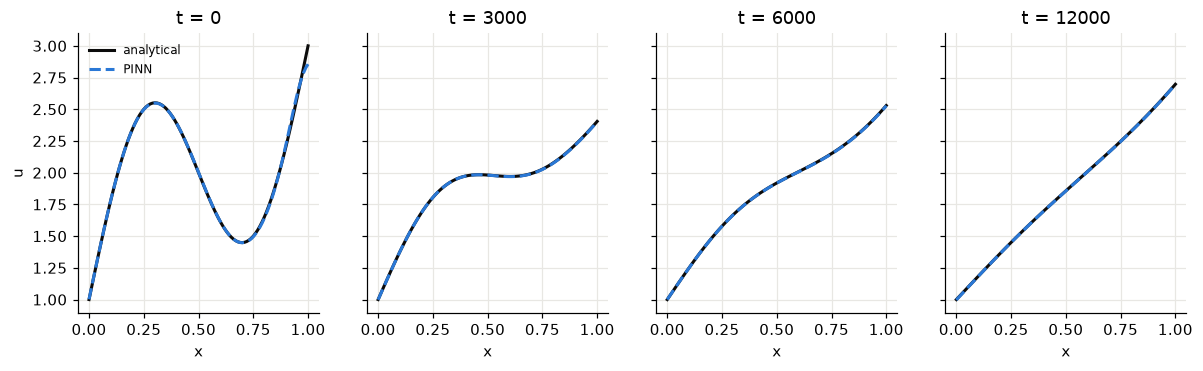

,t,max error,RMSE,x of max
0,0.000e+00,1.445e-01,1.902e-02,1.000e+00
1,3.000e+03,2.435e-03,1.361e-03,9.200e-01
2,6.000e+03,2.156e-03,1.344e-03,9.800e-01
3,1.200e+04,2.954e-03,1.197e-03,0.000e+00


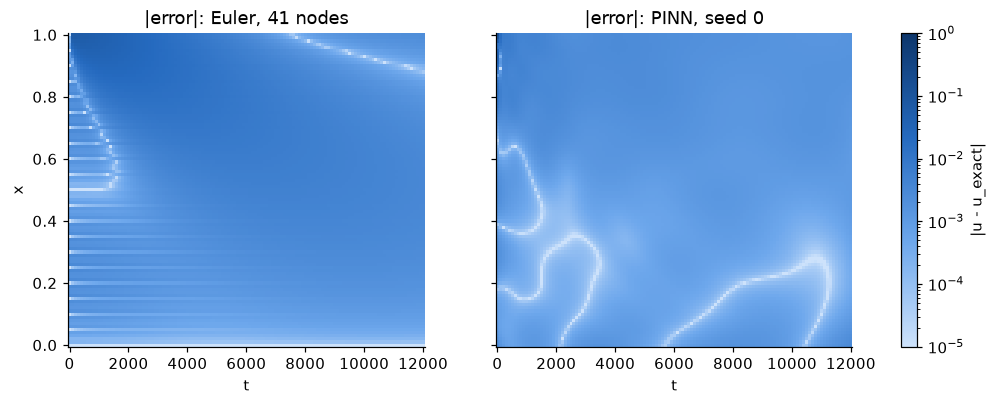

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, t in zip(axes, REPORT_TIMES):
    ax.plot(X_EVAL, reference(X_EVAL, t), color=COLORS["exact"], label="analytical")
    ax.plot(X_EVAL, predict(model, X_EVAL, t), "--", color=COLORS["pinn"], label="PINN")
    ax.set(title=f"t = {t:.0f}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend(loc="upper left", fontsize=8)
save_figure(fig, "c4_pinn_vs_analytic")

rows = []
for t in REPORT_TIMES:
    pred, ref = predict(model, X_EVAL, t), reference(X_EVAL, t)
    rows.append({"t": t, "max error": max_abs_error(pred, ref), "RMSE": rmse(pred, ref), "x of max": X_EVAL[np.argmax(np.abs(pred - ref))]})
save_table(pd.DataFrame(rows), "c4_pinn_errors")

# Absolute error maps of PINN and Euler on the common grid
times_map = np.linspace(0, T, 121)
exact_map = np.array([reference(X_EVAL, t) for t in times_map])
pinn_map = np.array([predict(model, X_EVAL, t) for t in times_map])
euler_map = np.array([np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t)) for t in times_map])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), sharey=True)
norm = LogNorm(vmin=1e-5, vmax=1)
for ax, field, title in ((axes[0], euler_map, "Euler, 41 nodes"), (axes[1], pinn_map, "PINN, seed 0")):
    image = ax.pcolormesh(times_map, X_EVAL, np.abs(field - exact_map).T + 1e-12, cmap=BLUES, norm=norm, shading="auto")
    ax.set(title=f"|error|: {title}", xlabel="t")
    ax.grid(False)
axes[0].set_ylabel("x")
fig.colorbar(image, ax=axes, label="|u - u_exact|")
save_figure(fig, "c4_error_maps")

,check,max|.|,RMS
0,"PINN: u(0,t) - 1",2.954e-03,1.216e-03
1,"PINN: u_x(1,t) - 2, autograd",3.016e-02,4.219e-03
2,Euler: U_0 - 1,0.000e+00,0.000e+00
3,Euler: (U_J - U_{J-1})/dx - 2,7.105e-15,7.105e-15
4,Euler: 2nd-order slope - 2,1.227e+00,1.662e-01


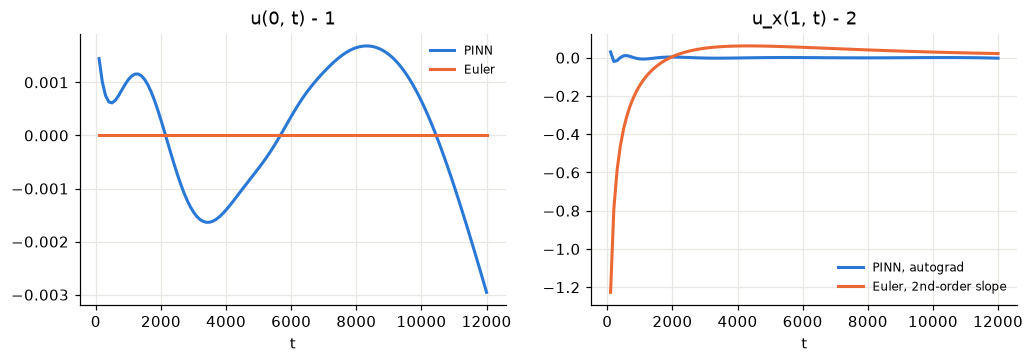

In [12]:
# Boundary-condition check on a common time grid, t > 0
times_bc = np.linspace(100, T, 120)
left_pinn, right_pinn = boundary_residuals(model, times_bc)
index = np.round(times_bc / (t_c[1] - t_c[0])).astype(int)
dx_c = x_c[1] - x_c[0]
left_euler = U_c[index, 0] - 1.0
one_sided = (U_c[index, -1] - U_c[index, -2]) / dx_c - 2.0  # what the scheme sets to zero by construction
second_order = (3 * U_c[index, -1] - 4 * U_c[index, -2] + U_c[index, -3]) / (2 * dx_c) - 2.0  # a more accurate slope estimate

def bc_row(label, values):
    return {"check": label, "max|.|": np.abs(values).max(), "RMS": np.sqrt(np.mean(values**2))}

bc_table = pd.DataFrame([
    bc_row("PINN: u(0,t) - 1", left_pinn),
    bc_row("PINN: u_x(1,t) - 2, autograd", right_pinn),
    bc_row("Euler: U_0 - 1", left_euler),
    bc_row("Euler: (U_J - U_{J-1})/dx - 2", one_sided),
    bc_row("Euler: 2nd-order slope - 2", second_order),
])
save_table(bc_table, "c4_boundary_residuals")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
axes[0].plot(times_bc, left_pinn, color=COLORS["pinn"], label="PINN")
axes[0].plot(times_bc, left_euler, color=COLORS["euler"], label="Euler")
axes[0].set(title="u(0, t) - 1", xlabel="t")
axes[1].plot(times_bc, right_pinn, color=COLORS["pinn"], label="PINN, autograd")
axes[1].plot(times_bc, second_order, color=COLORS["euler"], label="Euler, 2nd-order slope")
axes[1].set(title="u_x(1, t) - 2", xlabel="t")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
save_figure(fig, "c4_boundary_residuals")

**Conclusion.**
- **Profiles.** For $t\ge3000$ the PINN visually matches the analytical solution, with RMSE $1.2$-$1.4\cdot10^{-3}$ and maximum error $2$-$3\cdot10^{-3}$.
- **Initial time.** At $t=0$ the maximum error of 0.145 sits exactly at $x=1$. This is the corner incompatibility from section 2, with RMSE $1.9\cdot10^{-2}$. The error maps show different patterns: the Euler error originates at the right edge at early times and then diffuses inward, while the PINN error is spread over the domain without such structure, with sign-change lines.
- **Boundary conditions.** The PINN satisfies them only approximately: $u(0,t)-1$ has RMS $1.2\cdot10^{-3}$ and maximum $3\cdot10^{-3}$. At $t=12000$ the largest profile error is exactly at $x=0$. $u_x(1,t)-2$ has RMS $4.2\cdot10^{-3}$ and maximum $3\cdot10^{-2}$ (for $t\ge100$).
- **Euler for comparison.** The left condition holds exactly, and the one-sided difference on the right vanishes by construction, so that zero proves nothing. A fairer second-order slope estimate gives RMS 0.17 and a maximum of 1.2 at $t=100$. It is itself computed on the coarse grid, so it is an estimate, not an exact value.

---
# Part D. Comparative investigation
Common grid: $x_i=i/100$, $i=0,\dots,100$, so $M=101$ points. Reference: series of $N=2000$ terms. For $t\ge3000$ it has converged to machine precision (table in A4).

## D1. Error table
**Metric definitions** for a method with prediction $\hat u$ at time $t$:

$$E_{\max}(t)=\max_{1\le i\le M}\big|\hat u(x_i,t)-u_{\text{ser}}(x_i,t)\big|,\qquad\mathrm{RMSE}(t)=\sqrt{\frac1M\sum_{i=1}^{M}\big(\hat u(x_i,t)-u_{\text{ser}}(x_i,t)\big)^2}.$$

$E_{\max}$ shows the worst point and is sensitive to problems at the boundaries; RMSE shows the average error over the whole profile.

In [13]:
def error_row(label, predictor):
    row = {"method": label}
    for t in ERROR_TIMES:
        pred = predictor(t)
        row[f"max t={t:.0f}"] = max_abs_error(pred, reference(X_EVAL, t))
        row[f"RMSE t={t:.0f}"] = rmse(pred, reference(X_EVAL, t))
    return row

x_f, t_f, U_f = solve_euler(160, 9600, 1, store_every=2400)
x_2, t_2, U_2 = solve_euler(40, 600, 2, store_every=150)  # same grid, 2nd-order Neumann

d1 = pd.DataFrame([
    error_row("Euler, dx=1/40, dt=20", lambda t: np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))),
    error_row("PINN, seed 0, 20000 iterations", lambda t: predict(model, X_EVAL, t)),
])
save_table(d1, "d1_errors_main")

seed_models = {seed: load_run(f"main_seed{seed}")[0] for seed in SEEDS}
seed_rows = [error_row(f"seed {seed}", lambda t, m=m: predict(m, X_EVAL, t)) for seed, m in seed_models.items()]
seed_frame = pd.DataFrame(seed_rows)
numeric = seed_frame.drop(columns="method")

extended = pd.DataFrame([
    error_row("baseline: u_s(x)", lambda t: steady_state(X_EVAL)),
    error_row("Euler, dx=1/40, dt=20", lambda t: np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))),
    error_row("Euler, dx=1/40, dt=20, 2nd-order Neumann", lambda t: np.interp(X_EVAL, x_2, profile_at(t_2, U_2, t))),
    error_row("Euler, dx=1/160, dt=1.25", lambda t: np.interp(X_EVAL, x_f, profile_at(t_f, U_f, t))),
    error_row("PINN, 1000 iterations", lambda t: predict(load_run("baseline_1000")[0], X_EVAL, t)),
    {"method": "PINN, mean over 3 seeds", **numeric.mean().to_dict()},
    {"method": "PINN, std over 3 seeds", **numeric.std().to_dict()},
])
save_table(extended, "d1_errors_extended")

,method,max t=3000,RMSE t=3000,max t=6000,RMSE t=6000,max t=12000,RMSE t=12000
0,"Euler, dx=1/40, dt=20",1.995e-02,9.337e-03,8.519e-03,5.173e-03,3.381e-03,2.284e-03
1,"PINN, seed 0, 20000 iterations",2.435e-03,1.361e-03,2.156e-03,1.344e-03,2.954e-03,1.197e-03


,method,max t=3000,RMSE t=3000,max t=6000,RMSE t=6000,max t=12000,RMSE t=12000
0,baseline: u_s(x),5.958e-01,3.522e-01,4.707e-01,2.488e-01,3.028e-01,1.825e-01
1,"Euler, dx=1/40, dt=20",1.995e-02,9.337e-03,8.519e-03,5.173e-03,3.381e-03,2.284e-03
2,"Euler, dx=1/40, dt=20, 2nd-order Neumann",1.562e-03,9.889e-04,1.182e-03,6.502e-04,8.066e-04,4.125e-04
3,"Euler, dx=1/160, dt=1.25",5.907e-03,2.777e-03,2.751e-03,1.675e-03,1.160e-03,8.013e-04
4,"PINN, 1000 iterations",1.682e-01,5.851e-02,3.485e-02,1.853e-02,7.246e-02,2.719e-02
5,"PINN, mean over 3 seeds",2.461e-03,1.336e-03,2.154e-03,1.193e-03,1.973e-03,9.569e-04
6,"PINN, std over 3 seeds",7.438e-04,5.017e-04,1.145e-03,6.699e-04,9.786e-04,4.926e-04


**Conclusion.**
- **Specified methods.** The PINN with seed 0 is more accurate than the specified Euler scheme: by RMSE, 6.9 times at $t=3000$, 3.8 times at $t=6000$, 1.9 times at $t=12000$. By maximum error the gap nearly disappears at $t=12000$ ($3.0\cdot10^{-3}$ vs. $3.4\cdot10^{-3}$). The PINN's advantage shrinks with time because the Euler error decays along with the early boundary layer.
- **Where this gain comes from.** It is mostly explained by the first-order boundary condition, not by any superiority of the network. Euler on the same grid with a second-order condition is more accurate than the mean PINN at all three times, by both RMSE and maximum error (the best of the three seeds slightly beats it by RMSE). Grid $1/160$ is within a factor of two of the PINN by RMSE.
- **Minimal PINN.** With 1000 iterations it is 3-12 times worse than the specified Euler scheme.
- **Randomness.** The PINN spread over 3 seeds is about 40-55% of the mean, with seed 2 several times more accurate than seed 0 at the latest time. The Euler scheme is deterministic and has no spread. Seed 0 was fixed in advance and not chosen by its result.

## D2. Comparison of profiles, cost, boundary accuracy and sensitivity

In [14]:
# Computational cost. Euler uses the median of 5 repeats
euler_times = []
for _ in range(5):
    start = time.perf_counter()
    solve_euler(40, 600, 1, store_every=150)
    euler_times.append(time.perf_counter() - start)

start = time.perf_counter()
for t in ERROR_TIMES:
    predict(model, X_EVAL, t)
pinn_inference = (time.perf_counter() - start) / len(ERROR_TIMES)

start = time.perf_counter()
for t in ERROR_TIMES:
    np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))
euler_inference = (time.perf_counter() - start) / len(ERROR_TIMES)

def rmse_at(predictor, t=3000.0):
    return rmse(predictor(t), reference(X_EVAL, t))

def euler_cost(label, n_intervals, order):
    # Time and error come from the refinement table in B4
    row = refine[(refine["dx"] == 1 / n_intervals) & (refine["Neumann order"] == order)].iloc[0]
    steps = int(round(T / row["dt"]))
    return {"method": label, "training or solving, s": row["time, s"], "query of a 101-point profile, s": euler_inference,
            "numbers stored (all levels)": (n_intervals + 1) * (steps + 1), "RMSE t=3000": row["RMSE t=3000"]}

cost = pd.DataFrame([
    euler_cost("Euler, dx=1/40", 40, 1),
    euler_cost("Euler, dx=1/40, 2nd-order Neumann", 40, 2),
    euler_cost("Euler, dx=1/160", 160, 1),
    euler_cost("Euler, dx=1/320", 320, 1),
    {"method": "PINN, 20000 iterations", "training or solving, s": main_run["seconds"], "query of a 101-point profile, s": pinn_inference,
     "numbers stored (all levels)": n_params, "RMSE t=3000": rmse_at(lambda t: predict(model, X_EVAL, t))},
])
save_table(cost, "d2_cost")
print("Median of 5 Euler repeats, dx=1/40, s:", round(np.median(euler_times), 5))
print("PINN training vs. Euler on the specified grid, times longer:", round(main_run["seconds"] / np.median(euler_times)))
print("Same vs. Euler dx=1/320 at equal error at t=3000:", round(main_run["seconds"] / cost["training or solving, s"].iloc[3]))

# Value at the right end: this is where the Neumann condition matters
rows = []
for t in ERROR_TIMES:
    ref_right = reference(np.array([1.0]), t)[0]
    rows.append({"t": t, "exact u(1,t)": ref_right,
                 "|Euler - exact|": abs(profile_at(t_c, U_c, t)[-1] - ref_right),
                 "|PINN - exact|": abs(predict(model, np.array([1.0]), t)[0] - ref_right),
                 "|PINN(x=0) - 1|": abs(predict(model, np.array([0.0]), t)[0] - 1.0), "|Euler(x=0) - 1|": 0.0})
save_table(pd.DataFrame(rows), "d2_right_end")

,method,"training or solving, s","query of a 101-point profile, s",numbers stored (all levels),RMSE t=3000
0,"Euler, dx=1/40",1.962e-03,3.225e-05,24641,9.337e-03
1,"Euler, dx=1/40, 2nd-order Neumann",2.086e-03,3.225e-05,24641,9.889e-04
2,"Euler, dx=1/160",3.391e-02,3.225e-05,1545761,2.777e-03
3,"Euler, dx=1/320",1.404e-01,3.225e-05,12326721,1.424e-03
4,"PINN, 20000 iterations",3.584e+02,3.250e-04,2241,1.361e-03


Median of 5 Euler repeats, dx=1/40, s: 0.00192
PINN training vs. Euler on the specified grid, times longer: 187090
Same vs. Euler dx=1/320 at equal error at t=3000: 2553


,t,"exact u(1,t)",|Euler - exact|,|PINN - exact|,|PINN(x=0) - 1|,|Euler(x=0) - 1|
0,3.000e+03,2.404e+00,1.857e-02,2.283e-03,1.443e-03,0.000e+00
1,6.000e+03,2.529e+00,2.891e-03,2.143e-03,3.570e-04,0.000e+00
2,1.200e+04,2.697e+00,2.315e-03,1.585e-03,2.954e-03,0.000e+00


### Early times and the corner $(1,0)$
Expectation before computing: the Euler error sits near $x=1$ and falls once the layer of thickness $\sqrt{\beta t}$ becomes wider than the grid step. For the PINN the error as $t\to0$ should concentrate at the same corner.

,t,sqrt(beta t),max Euler 1/40,x (Euler 1/40),max Euler 1/160,max PINN,x (PINN),RMSE PINN
0,0.000e+00,0.000e+00,2.951e-03,7.400e-01,1.847e-04,1.445e-01,1.000e+00,1.902e-02
1,2.000e+01,1.414e-02,5.546e-02,1.000e+00,1.831e-02,6.417e-02,1.000e+00,1.125e-02
2,1.000e+02,3.162e-02,6.591e-02,1.000e+00,1.829e-02,1.674e-02,1.000e+00,3.591e-03
3,5.000e+02,7.071e-02,5.819e-02,1.000e+00,1.574e-02,6.001e-03,9.800e-01,2.455e-03
4,1.000e+03,1.000e-01,4.701e-02,1.000e+00,1.287e-02,4.330e-03,1.000e+00,1.954e-03
5,3.000e+03,1.732e-01,1.995e-02,9.500e-01,5.907e-03,2.435e-03,9.200e-01,1.361e-03


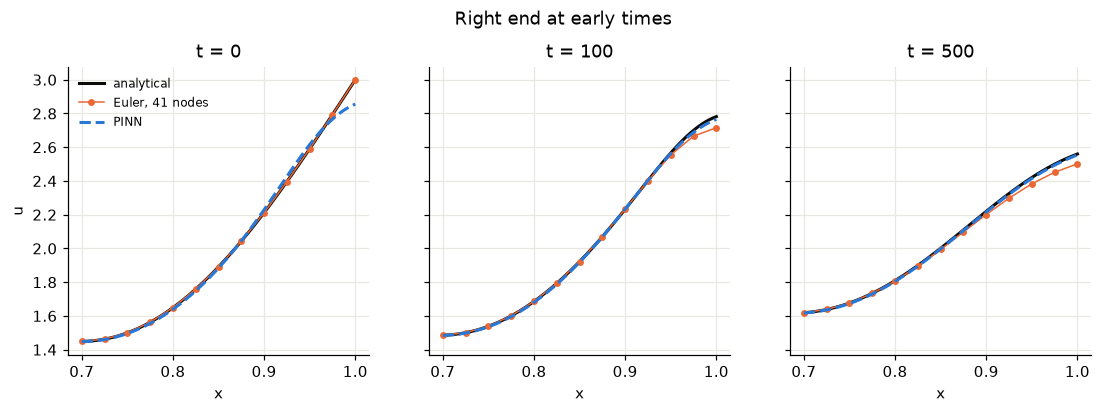

In [15]:
early = [0.0, 20.0, 100.0, 500.0, 1000.0, 3000.0]
x_e, t_e, U_e = solve_euler(160, 9600, 1, store_every=16)  # storage step 20, as on the coarse grid
rows = []
for t in early:
    ref = reference(X_EVAL, t)
    euler_c = np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))
    euler_f = np.interp(X_EVAL, x_e, profile_at(t_e, U_e, t))
    pinn_p = predict(model, X_EVAL, t)
    rows.append({"t": t, "sqrt(beta t)": np.sqrt(BETA * t),
                 "max Euler 1/40": max_abs_error(euler_c, ref), "x (Euler 1/40)": X_EVAL[np.argmax(np.abs(euler_c - ref))],
                 "max Euler 1/160": max_abs_error(euler_f, ref),
                 "max PINN": max_abs_error(pinn_p, ref), "x (PINN)": X_EVAL[np.argmax(np.abs(pinn_p - ref))],
                 "RMSE PINN": rmse(pinn_p, ref)})
save_table(pd.DataFrame(rows), "d2_early_times")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
x_zoom = np.linspace(0.7, 1.0, 301)
for ax, t in zip(axes, (0.0, 100.0, 500.0)):
    ax.plot(x_zoom, reference(x_zoom, t), color=COLORS["exact"], label="analytical")
    ax.plot(x_c[x_c >= 0.7 - 1e-9], profile_at(t_c, U_c, t)[x_c >= 0.7 - 1e-9], "o-", ms=3.5, lw=1, color=COLORS["euler"], label="Euler, 41 nodes")
    ax.plot(x_zoom, predict(model, x_zoom, t), "--", color=COLORS["pinn"], label="PINN")
    ax.set(title=f"t = {t:.0f}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend(fontsize=8)
fig.suptitle("Right end at early times", y=1.03)
save_figure(fig, "d2_early_corner")

**D2 conclusions.**

| Criterion | Explicit Euler | PINN |
|---|---|---|
| **Profiles** | Match the analytical series, a visible difference only at the right end at early times | Match for $t\ge100$, the largest error at small $t$ at $x=1$ |
| **Cost** | 2-3 ms on the specified grid, 0.1-0.2 s on grid $1/320$ | About 6 minutes of training on the same CPU, then under 1 ms per profile |
| **Storage** | Solution only at the nodes, interpolation needed | 2241 numbers, a continuous function with exact derivatives |
| **Boundaries** | Dirichlet exact, Neumann with error $O(\Delta x)$ | Both approximate, through a penalty |
| **Sensitivity** | Deterministic, backed by theory: $s\le\frac12$, known order | Depends on weights, iterations and seed, no theoretical error estimate |

**Cost.** PINN training takes about $10^5$ times longer than solving on the specified grid. At equal error (RMSE about $1.4\cdot10^{-3}$ at $t=3000$), Euler on grid $1/320$ is still more than 1000 times faster. In operation count each refinement step costs 8 times more (4 times more steps and 2 times more nodes), while measured time grows about 4 times: on such small arrays most of the time goes to the Python loop.

**PINN sensitivity.** The network reaches the required accuracy only with suitable settings: without physics scaling RMSE is 0.6-0.8, with 1000 iterations about $6\cdot10^{-2}$. The loss value also cannot be converted directly into a solution error, whereas the order of the Euler error is known in advance.

**Early times.** For scheme $1/40$ the error peaks at $x=1$ and stays at 0.05-0.07 for $t=20$-$500$, because the boundary error $\frac{\Delta x}{2}u_{xx}(1,t)$ is large while the layer is thin. On grid $1/160$ it is 3-4 times smaller. The PINN behaves differently: 0.145 at $t=0$ and 0.064 at $t=20$, the level of coarse Euler or worse, but already $1.7\cdot10^{-2}$ at $t=100$ and falling faster afterwards. A comparison at small $t$ therefore cannot be extended to the whole interval: it mostly tells how a method copes with the slope jump. Also, at $t=0$ Euler is exact at the nodes simply by construction.

**Where a PINN is genuinely useful.** This problem is one-dimensional and linear, so it is hard for a numerical scheme to lose here. PINN strengths show up elsewhere: no mesh is needed, measurements can be added to the loss, unknown parameters (such as $\beta$) can be estimated, and cost grows less sharply with dimension. These advantages were not tested in this work and are stated as known properties of the method.

## D3. Controlled experiment: boundary-loss weight
**What changes:** only $\lambda_b=\lambda_{\text{D}}=\lambda_{\text{N}}\in\{0.1,1,10,100\}$. **What is fixed:** architecture, iteration count, learning rate, points, and the physics and initial-condition weights. Each value uses 3 seeds, to separate the effect from random spread.

**Expectation before computing:** with small $\lambda_b$ the network holds the boundaries less well. With large $\lambda_b$ the boundaries hold more accurately, but the optimizer pays less attention to physics and the initial condition. An optimum is expected somewhere in the middle.

,lambda_b,L_IC,T^2 L_phys,"RMS u(0,t)-1","RMS u_x(1,t)-2",RMSE t=3000,RMSE t=6000,RMSE t=12000,std RMSE t=3000,std RMSE t=6000,std RMSE t=12000
0,1.000e-01,2.793e-04,1.231e-04,2.261e-03,1.368e-02,1.438e-03,1.275e-03,1.258e-03,7.226e-04,5.638e-04,3.808e-04
1,1.000e+00,3.689e-04,1.210e-04,1.289e-03,3.148e-03,1.336e-03,1.193e-03,9.569e-04,5.017e-04,6.699e-04,4.926e-04
2,1.000e+01,1.444e-03,4.589e-04,7.621e-04,1.844e-03,2.187e-03,1.996e-03,1.811e-03,4.367e-04,9.297e-04,6.121e-04
3,1.000e+02,3.921e-02,7.033e-03,1.408e-03,1.559e-03,2.270e-02,1.302e-02,8.575e-03,1.069e-02,8.017e-03,6.179e-03


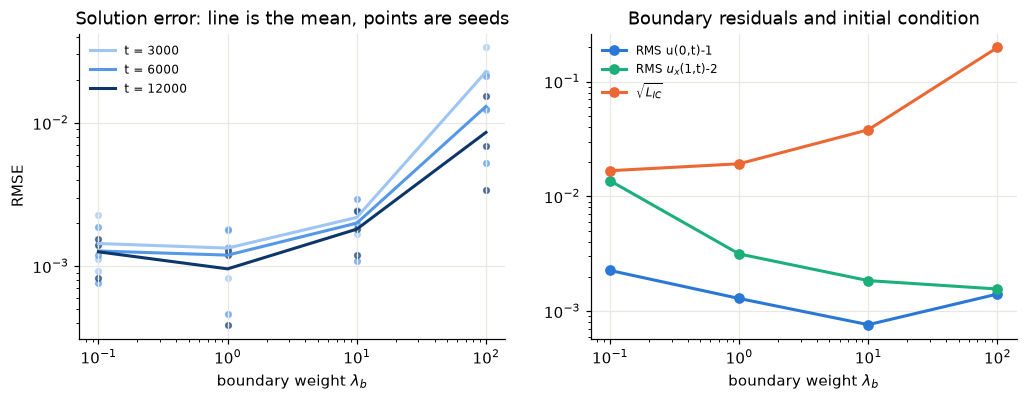

In [16]:
rows = []
for weight in BOUNDARY_WEIGHTS:
    for seed in SEEDS:
        name = f"main_seed{seed}" if weight == 1.0 else f"boundary{weight:g}_seed{seed}"
        m, run = load_run(name)
        left, right = boundary_residuals(m, times_bc)
        row = {"lambda_b": weight, "seed": seed, "L_IC": np.mean(run["history"]["initial"][-100:]),
               "T^2 L_phys": T**2 * np.mean(run["history"]["physics"][-100:]),
               "RMS u(0,t)-1": np.sqrt(np.mean(left**2)), "RMS u_x(1,t)-2": np.sqrt(np.mean(right**2))}
        for t in ERROR_TIMES:
            row[f"RMSE t={t:.0f}"] = rmse(predict(m, X_EVAL, t), reference(X_EVAL, t))
        rows.append(row)
d3_all = pd.DataFrame(rows)
d3_all.to_csv(TABLES / "d3_boundary_weight_all_seeds.csv", index=False)
summary_columns = [c for c in d3_all.columns if c not in ("lambda_b", "seed")]
d3_mean = d3_all.groupby("lambda_b")[summary_columns].mean().reset_index()
d3_std = d3_all.groupby("lambda_b")[[f"RMSE t={t:.0f}" for t in ERROR_TIMES]].std().add_prefix("std ").reset_index()
save_table(d3_mean.merge(d3_std, on="lambda_b"), "d3_boundary_weight_summary")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for t, color in zip(ERROR_TIMES, ("#9ec5f4", "#5598e7", "#0d366b")):
    column = f"RMSE t={t:.0f}"
    axes[0].scatter(d3_all["lambda_b"], d3_all[column], s=14, color=color, alpha=0.6)
    axes[0].plot(d3_mean["lambda_b"], d3_mean[column], color=color, label=f"t = {t:.0f}")
axes[0].set(xscale="log", yscale="log", xlabel="boundary weight $\\lambda_b$", ylabel="RMSE", title="Solution error: line is the mean, points are seeds")
axes[0].legend(fontsize=8)
axes[1].plot(d3_mean["lambda_b"], d3_mean["RMS u(0,t)-1"], "o-", color=COLORS["pinn"], label="RMS u(0,t)-1")
axes[1].plot(d3_mean["lambda_b"], d3_mean["RMS u_x(1,t)-2"], "o-", color=COLORS["aqua"], label="RMS $u_x$(1,t)-2")
axes[1].plot(d3_mean["lambda_b"], np.sqrt(d3_mean["L_IC"]), "o-", color=COLORS["euler"], label="$\\sqrt{L_{IC}}$")
axes[1].set(xscale="log", yscale="log", xlabel="boundary weight $\\lambda_b$", title="Boundary residuals and initial condition")
axes[1].legend(fontsize=8)
save_figure(fig, "d3_boundary_weight")

**Conclusion.**
- **Boundary conditions behave as expected.** As $\lambda_b$ grows from 0.1 to 100, RMS $u_x(1,t)-2$ falls from $1.4\cdot10^{-2}$ to $1.6\cdot10^{-3}$. For $u(0,t)-1$ the picture is non-monotonic: the best value is $7.6\cdot10^{-4}$ at $\lambda_b=10$.
- **Price of a large weight.** At $\lambda_b=100$ the optimizer almost stops learning the rest: $L_{\text{IC}}$ grows 100 times ($3.9\cdot10^{-2}$ vs. $3.7\cdot10^{-4}$) and RMSE at $t=3000$ grows 17 times ($2.3\cdot10^{-2}$ vs. $1.3\cdot10^{-3}$).
- **Small values are nearly equivalent.** The RMSE difference between $\lambda_b=0.1$ and $1$ ($1.44$ and $1.34\cdot10^{-3}$ at $t=3000$) is smaller than the spread between seeds ($\sim6\cdot10^{-4}$), and $\lambda_b=10$ is about 1.6 times worse, almost at the edge of the spread. So the expected sharp optimum is absent, and we can only say with confidence that $\lambda_b=100$ is clearly worse. Three seeds are too few for finer conclusions.
- **Interpretation.** Solution accuracy is determined by the balance of all terms, not by boundary accuracy alone. A small boundary residual by itself does not guarantee a small error in the domain, as $\lambda_b=100$ shows. The value $\lambda_b=1$ was kept as the main one in advance and was not chosen from this table.

---
# Summary
- **Analytical.** $u(x,t)=2x+1+\sum b_n\sin(k_nx)e^{-\beta k_n^2t}$ with $b_n=(-1)^{n+1}4\pi/(4\pi^2-k_n^2)$. This is the reference: for $t\ge3000$ the series converges to machine precision even at small $N$. The steady profile is not yet reached at $t=T$ ($\max|v|=0.30$).
- **Euler.** The simplest and cheapest method, stable at $s=0.32$. The specified scheme is first-order because of the boundary condition: RMSE $9.3\cdot10^{-3}$ at $t=3000$ in 2-3 ms. Replacing only the boundary formula gives second order and a 9 times smaller error.
- **PINN.** After physics scaling and 20000 iterations, RMSE is about $10^{-3}$. That is more accurate than the specified Euler scheme, roughly equal to the scheme on grids $1/160$-$1/320$, and behind the second-order scheme on grid $1/40$. The price: about 6 minutes of training, dependence on settings and seed, and only approximate boundary conditions.
- **Main conclusion.** For this problem the classical scheme is better in accuracy per cost. The PINN showed that it can solve the problem without labels, but its result depends on scaling and settings, and it is harder to verify without a reference. Its gain over the baseline Euler scheme is explained by that scheme's first-order boundary condition, not by any superiority of the neural network.

**Limitations.** Timings come from one machine, and the PINN was timed once (Apple M4, one CPU thread). The spread over 3 seeds gives only a rough estimate of training randomness. PINN settings were tuned by a small manual search for this problem only, and a different formulation would need new tuning.

---
# Appendix. Source code
The full code of `src/`, which the notebook imports. It is listed here so that all code can be read from this notebook. The Euler scheme and the PINN training are written directly from the formulas above; PyTorch is used only for the network layers, automatic differentiation and the Adam optimizer.

### `src/problem.py`: Problem parameters

```python
"""Problem statement: the same parameters for all three methods."""
import numpy as np

BETA = 1e-5  # thermal diffusivity
T = 12_000.0  # final time
U_LEFT = 1.0  # Dirichlet condition: u(0, t) = 1
UX_RIGHT = 2.0  # Neumann condition: u_x(1, t) = 2
REPORT_TIMES = (0.0, 3000.0, 6000.0, 12000.0)  # reporting times


def initial_condition(x):
    """Initial profile u(x, 0) = 2x + sin(2 pi x) + 1."""
    return 2.0 * x + np.sin(2.0 * np.pi * x) + 1.0


def steady_state(x):
    """Steady-state solution u_s(x) = 2x + 1."""
    return 2.0 * x + 1.0
```

### `src/analytic.py`: Analytical series

```python
"""Analytical solution: u(x, t) = u_s(x) + a series over the eigenfunctions."""
import numpy as np

from .problem import BETA, steady_state


def wave_numbers(n_terms):
    """Wavenumbers k_n = (n + 1/2) * pi for n = 0, ..., n_terms - 1."""
    return (np.arange(n_terms) + 0.5) * np.pi


def series_coefficients(n_terms):
    """Coefficients b_n = (-1)^(n+1) * 4 pi / (4 pi^2 - k_n^2)."""
    k = wave_numbers(n_terms)
    signs = (-1.0) ** (np.arange(n_terms) + 1)
    return signs * 4.0 * np.pi / (4.0 * np.pi**2 - k**2)


def transient(x, t, n_terms=2000, beta=BETA):
    """Transient part v(x, t) as a series truncated to n_terms terms."""
    x = np.asarray(x, dtype=float)
    k = wave_numbers(n_terms)
    b = series_coefficients(n_terms)
    # Matrix rows correspond to the points x, columns to the indices n
    return np.sin(np.outer(x, k)) @ (b * np.exp(-beta * k**2 * t))


def exact_solution(x, t, n_terms=2000, beta=BETA):
    """Full solution u(x, t) = u_s(x) + v(x, t) at time t."""
    x = np.asarray(x, dtype=float)
    return steady_state(x) + transient(x, t, n_terms, beta)
```

### `src/euler.py`: Explicit Euler scheme (B2)

```python
"""Explicit Euler scheme (FTCS) for the heat equation, written by hand."""
import numpy as np

from .problem import BETA, T, U_LEFT, UX_RIGHT, initial_condition


def solve_euler(n_intervals=40, n_steps=600, neumann_order=1, store_every=1, beta=BETA, t_end=T):
    """Solve the problem and return x, times, U (each row of U is one time level).

    n_intervals: number of intervals in x, there is one more node.
    n_steps: number of time steps.
    neumann_order: 1 means U_J = U_{J-1} + 2 dx, 2 means a ghost node beyond the boundary.
    store_every: keep every such step, to avoid holding all levels in memory.
    """
    dx = 1.0 / n_intervals
    dt = t_end / n_steps
    s = beta * dt / dx**2  # diffusion number, stability requires s <= 1/2

    x = np.linspace(0.0, 1.0, n_intervals + 1)
    u = initial_condition(x)  # level m = 0 is taken exactly from the initial condition
    saved_u, saved_t = [u.copy()], [0.0]

    for m in range(1, n_steps + 1):
        new = u.copy()
        # Interior nodes: U_j^{m+1} = U_j^m + s (U_{j-1}^m - 2 U_j^m + U_{j+1}^m)
        new[1:-1] = u[1:-1] + s * (u[:-2] - 2.0 * u[1:-1] + u[2:])
        new[0] = U_LEFT  # left boundary: Dirichlet condition
        if neumann_order == 1:
            # One-sided difference: (U_J - U_{J-1}) / dx = 2, accuracy O(dx)
            new[-1] = new[-2] + UX_RIGHT * dx
        elif neumann_order == 2:
            # Ghost node U_{J+1} = U_{J-1} + 2 dx * 2, accuracy O(dx^2)
            new[-1] = u[-1] + 2.0 * s * (u[-2] - u[-1] + UX_RIGHT * dx)
        else:
            raise ValueError("neumann_order must be 1 or 2")
        u = new
        if m % store_every == 0:
            saved_u.append(u.copy())
            saved_t.append(m * dt)

    return x, np.array(saved_t), np.array(saved_u)


def diffusion_number(n_intervals, n_steps, beta=BETA, t_end=T):
    """Compute s = beta dt / dx^2 for the given grid."""
    return beta * (t_end / n_steps) * n_intervals**2


def profile_at(times, field, t):
    """Return the profile at the nearest stored level and check that the time matches."""
    index = int(np.argmin(np.abs(times - t)))
    if abs(times[index] - t) > 1e-9:
        raise ValueError(f"time t={t} was not stored")
    return field[index]
```

### `src/metrics.py`: Error metrics (D1)

```python
"""Metrics for comparison with the reference on the common grid."""
import numpy as np


def max_abs_error(pred, ref):
    """Maximum absolute error: max_i |pred_i - ref_i|."""
    return float(np.max(np.abs(np.asarray(pred) - np.asarray(ref))))


def rmse(pred, ref):
    """Root-mean-square error: sqrt(1/M * sum_i (pred_i - ref_i)^2)."""
    return float(np.sqrt(np.mean((np.asarray(pred) - np.asarray(ref)) ** 2)))
```

### `src/pinn.py`: PINN: network, losses, training (C2)

```python
"""PINN for the heat equation. The exact solution is not used in training."""
import time
from dataclasses import dataclass

import numpy as np
import torch
from torch import nn

from .problem import BETA, T, U_LEFT, UX_RIGHT

DTYPE = torch.float64  # double precision: the physical residual is very small in magnitude


@dataclass
class PINNConfig:
    """All settings of one run, so they can be recorded in the report."""

    hidden_layers: int = 3
    hidden_units: int = 32
    n_interior: int = 2000  # interior collocation points
    n_initial: int = 200  # points at tau = 0
    n_boundary: int = 200  # points on each boundary x = 0 and x = 1
    iterations: int = 20000
    lr: float = 1e-3  # initial Adam learning rate
    lr_final: float = 1e-5  # final learning rate of the cosine decay
    weight_physics: float = T**2  # this weight equals the dimensionless residual u_tau - beta T u_xx
    weight_initial: float = 1.0
    weight_dirichlet: float = 1.0
    weight_neumann: float = 1.0
    resample: bool = False  # True: new random points at every iteration
    seed: int = 0
    log_every: int = 10


class PINN(nn.Module):
    """Fully connected network (x, tau) -> u with tanh activation."""

    def __init__(self, hidden_layers=3, hidden_units=32):
        super().__init__()
        layers = [nn.Linear(2, hidden_units), nn.Tanh()]
        for _ in range(hidden_layers - 1):
            layers += [nn.Linear(hidden_units, hidden_units), nn.Tanh()]
        layers.append(nn.Linear(hidden_units, 1))
        self.net = nn.Sequential(*layers)
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)  # initial weight scale suited to tanh
                nn.init.zeros_(layer.bias)

    def forward(self, x, tau):
        # Map inputs from [0, 1] to [-1, 1], tanh trains noticeably more easily this way
        inputs = torch.cat([2.0 * x - 1.0, 2.0 * tau - 1.0], dim=1)
        return self.net(inputs)


def initial_tensor(x):
    """Initial condition for tensors, a torch copy of the formula in problem.py."""
    return 2.0 * x + torch.sin(2.0 * torch.pi * x) + 1.0


def gradients(u, x, tau=None, second=False):
    """Automatic differentiation: returns u_x, and u_tau and u_xx on request."""
    # create_graph=True builds a graph of the derivatives, so backward can reach the weights through them
    if tau is not None:
        u_x, u_tau = torch.autograd.grad(u.sum(), (x, tau), create_graph=True)
    else:
        u_x = torch.autograd.grad(u.sum(), x, create_graph=True)[0]
        u_tau = None
    u_xx = torch.autograd.grad(u_x.sum(), x, create_graph=True)[0] if second else None
    return u_x, u_tau, u_xx


def physics_residual(model, x, tau, beta=BETA, t_end=T):
    """Residual on the physical scale: r = (1 / T) u_tau - beta u_xx."""
    x = x.clone().requires_grad_(True)
    tau = tau.clone().requires_grad_(True)
    u = model(x, tau)
    _, u_tau, u_xx = gradients(u, x, tau, second=True)
    return u_tau / t_end - beta * u_xx


def sample_points(cfg, generator):
    """Uniform random points for all four parts of the loss."""

    def uniform(n):
        return torch.rand(n, 1, generator=generator, dtype=DTYPE)

    return {
        "x_r": uniform(cfg.n_interior),
        "tau_r": uniform(cfg.n_interior),
        "x_ic": uniform(cfg.n_initial),
        "tau_b": uniform(cfg.n_boundary),
    }


def loss_terms(model, points):
    """Compute the four mean-squared terms of the loss."""
    # 1. Equation inside the domain
    residual = physics_residual(model, points["x_r"], points["tau_r"])
    loss_physics = (residual**2).mean()

    # 2. Initial condition at tau = 0
    x_ic = points["x_ic"]
    pred_ic = model(x_ic, torch.zeros_like(x_ic))
    loss_initial = ((pred_ic - initial_tensor(x_ic)) ** 2).mean()

    # 3. Left boundary: u(0, tau) = 1
    tau_b = points["tau_b"]
    pred_left = model(torch.zeros_like(tau_b), tau_b)
    loss_dirichlet = ((pred_left - U_LEFT) ** 2).mean()

    # 4. Right boundary: u_x(1, tau) = 2
    x_right = torch.ones_like(tau_b).requires_grad_(True)
    pred_right = model(x_right, tau_b)
    u_x, _, _ = gradients(pred_right, x_right)
    loss_neumann = ((u_x - UX_RIGHT) ** 2).mean()

    return {
        "physics": loss_physics,
        "initial": loss_initial,
        "dirichlet": loss_dirichlet,
        "neumann": loss_neumann,
    }


def train_pinn(cfg):
    """Train the network and return the model, loss history and training time in seconds."""
    torch.manual_seed(cfg.seed)
    generator = torch.Generator().manual_seed(cfg.seed)
    model = PINN(cfg.hidden_layers, cfg.hidden_units).to(DTYPE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.iterations, eta_min=cfg.lr_final)

    weights = {
        "physics": cfg.weight_physics,
        "initial": cfg.weight_initial,
        "dirichlet": cfg.weight_dirichlet,
        "neumann": cfg.weight_neumann,
    }
    points = sample_points(cfg, generator)
    history = {"iteration": [], "total": [], "physics": [], "initial": [], "dirichlet": [], "neumann": []}

    start = time.perf_counter()
    for iteration in range(1, cfg.iterations + 1):
        if cfg.resample:
            points = sample_points(cfg, generator)
        optimizer.zero_grad()
        terms = loss_terms(model, points)
        total = sum(weights[name] * value for name, value in terms.items())
        total.backward()  # backward goes through all the derivatives to the network weights
        optimizer.step()
        scheduler.step()

        if iteration == 1 or iteration % cfg.log_every == 0:
            history["iteration"].append(iteration)
            history["total"].append(total.item())
            for name, value in terms.items():
                history[name].append(value.item())
    train_seconds = time.perf_counter() - start

    return model, {key: np.array(value) for key, value in history.items()}, train_seconds


def predict(model, x, t, t_end=T):
    """Prediction on the grid x (numpy) at physical time t."""
    x_tensor = torch.as_tensor(np.asarray(x), dtype=DTYPE).reshape(-1, 1)
    tau_tensor = torch.full_like(x_tensor, t / t_end)
    with torch.no_grad():
        return model(x_tensor, tau_tensor).numpy().ravel()


def boundary_residuals(model, times, t_end=T):
    """Return u(0, t) - 1 and u_x(1, t) - 2 for an array of times."""
    tau = torch.as_tensor(np.asarray(times) / t_end, dtype=DTYPE).reshape(-1, 1)
    left = model(torch.zeros_like(tau), tau).detach().numpy().ravel() - U_LEFT
    x_right = torch.ones_like(tau).requires_grad_(True)
    u_x, _, _ = gradients(model(x_right, tau), x_right)
    return left, u_x.detach().numpy().ravel() - UX_RIGHT
```

### `src/experiments.py`: List of runs and cache

```python
"""PINN runs with a cache: a trained run is stored in weights/ and is not recomputed."""
import multiprocessing as mp
from dataclasses import asdict
from pathlib import Path

import torch

from .pinn import PINN, DTYPE, PINNConfig, train_pinn

WEIGHTS_DIR = Path(__file__).resolve().parents[1] / "weights"
SEEDS = (0, 1, 2)
BOUNDARY_WEIGHTS = (0.1, 1.0, 10.0, 100.0)  # boundary weight values in experiment D3


def all_runs():
    """Full list of runs in this work: file name and settings."""
    runs = {f"main_seed{seed}": PINNConfig(seed=seed) for seed in SEEDS}
    # The reference minimum: same settings, but 1000 iterations
    runs["baseline_1000"] = PINNConfig(iterations=1000)
    # Without physics scaling: residual weight 1 instead of T^2
    runs["no_physics_weight"] = PINNConfig(weight_physics=1.0)
    # Control: new random points at every iteration
    runs["resample_seed0"] = PINNConfig(resample=True)
    # D3: change only the weight of the two boundary losses
    for weight in BOUNDARY_WEIGHTS:
        if weight == 1.0:
            continue  # this variant coincides with main_seed*
        for seed in SEEDS:
            runs[f"boundary{weight:g}_seed{seed}"] = PINNConfig(
                seed=seed, weight_dirichlet=weight, weight_neumann=weight
            )
    return runs


def run_path(name):
    """Path to the file of a run."""
    return WEIGHTS_DIR / f"{name}.pt"


def train_and_save(name, cfg):
    """Train one run on one thread and save the weights, history and time."""
    torch.set_num_threads(1)  # one thread, so the time is comparable with the numpy Euler code
    model, history, seconds = train_pinn(cfg)
    WEIGHTS_DIR.mkdir(exist_ok=True)
    torch.save(
        {"state_dict": model.state_dict(), "config": asdict(cfg), "history": history, "seconds": seconds},
        run_path(name),
    )
    return name, seconds


def _worker(item):
    return train_and_save(*item)


def ensure_trained(processes=4):
    """Train only the runs that do not exist yet. Returns the list of runs trained now."""
    runs = all_runs()
    done = []
    # main_seed0 is trained alone, without parallel load: its time goes into the report
    if not run_path("main_seed0").exists():
        done.append(train_and_save("main_seed0", runs["main_seed0"]))
    missing = [(name, cfg) for name, cfg in runs.items() if not run_path(name).exists()]
    if missing:
        # spawn is needed because fork together with torch is unreliable on macOS
        with mp.get_context("spawn").Pool(processes) as pool:
            for result in pool.imap_unordered(_worker, missing):
                done.append(result)
                print("trained:", *result, flush=True)
    return done


def load_run(name):
    """Load a run and return the model and a dict with settings, history and time."""
    run = torch.load(run_path(name), weights_only=False)
    config = PINNConfig(**run["config"])
    model = PINN(config.hidden_layers, config.hidden_units).to(DTYPE)
    model.load_state_dict(run["state_dict"])
    model.eval()
    return model, run
```